# Tutorial 05: Topology of tight-binding models

In this tutorial you compute the topological invariants of three honeycomb models: the quantised spin Hall conductivity (SHC) of the Kane–Mele model, the Berry phases of gapped graphene on loops around a valley, and the Chern numbers that separate gapped graphene, a trivial insulator, from the Haldane model, a Chern insulator. Each model is a tight-binding Hamiltonian $H_{\alpha\beta}(\mathbf{R})$ that PAOFLOW builds from a few parameters, in contrast to the DFT Hamiltonian of [Tutorial 01](tutorial01.ipynb), so every result can be checked against its analytic value before you trust the same calls on a material. The methods are {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.spin_Hall` and {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.berry_phase`, after the calls of Tutorial 01 from `bands()` to `adaptive_smearing()`.

**What you will compute**

- The spin–orbit gap of the Kane–Mele model and the spin Berry curvature of its occupied bands
- The spin Hall conductivity as a function of energy, and its quantised plateau inside the gap
- The Berry phase of a band on a closed loop in k-space, from the overlaps of its Bloch states
- How the Berry curvature of a gapped Dirac cone spreads around the valley
- The Chern number as the Berry flux through the whole Brillouin zone, for a trivial and a topological insulator

:::{tip}
{download}`Download this notebook <tutorial05.ipynb>`. It builds every model in code, so it needs no input files and has no setup cell; it runs in about one minute on 4 cores. Section 4 builds the Haldane model with the PythTB package, which you install with the `pythtb` extra, `pip install "PAOFLOW[pythtb]"`. This tutorial assumes [Tutorial 01](tutorial01.ipynb), and [How to run PAOFLOW on a tight-binding model](../howtos/tight-binding-model.md) for how a model replaces the DFT steps.
:::

## Required input

You give each model as a dictionary passed to the `model` argument of `PAOFLOW`, with its parameters in eV; the [tight-binding how-to](../howtos/tight-binding-model.md#choosing-the-model) lists the models and their parameters. All three are two-dimensional honeycomb lattices without hopping along $z$. You therefore interpolate on meshes with a single k-point along $z$, and you give the k-path and the loops in crystal coordinates of the two in-plane reciprocal vectors, with $K = (\tfrac23, \tfrac13)$ and $K' = (\tfrac13, \tfrac23)$. A model has no electron count of its own, and its energy zero is the zero of its on-site energies, which for these models is the middle of the gap at half filling.

## 1. The Kane–Mele model and its spin–orbit gap

You start from the model of [C. L. Kane and E. J. Mele, Phys. Rev. Lett. 95, 226801 (2005)](https://doi.org/10.1103/PhysRevLett.95.226801): graphene with one orbital per site and both spins, in which spin–orbit coupling enters as a spin-dependent hopping between second neighbours,

$$
H = t \sum_{\langle ij \rangle} c_i^\dagger c_j
  + i\lambda_{SO} \sum_{\langle\langle ij \rangle\rangle} \nu_{ij}\, c_i^\dagger s_z c_j
  + t\, v \sum_i \xi_i\, c_i^\dagger c_i
  + H_R ,
$$

with $\lambda_{SO}$ = `soc_par`, $v$ = `v_par`, $\xi_i = \pm 1$ on the two sublattices, and $\nu_{ij} = \pm 1$ depending on whether the path from $j$ to $i$ through their common neighbour turns left or right. `r_par` sets the Rashba term $H_R$. With `r_par=0` the spin component $s_z$ is conserved, so the model splits into two spinless honeycomb models, one per spin, whose second-neighbour hoppings $\pm i\lambda_{SO}$ have opposite signs. Each of them is a Haldane model (Section 4), and each opens a gap $6\sqrt{3}\,\lambda_{SO}$ at $K$ and $K'$.

The cell below builds the model with $t = 1$ eV and $\lambda_{SO} = 0.1$ eV, computes its bands, and then prepares the band energies and velocities on a $60 \times 60$ mesh as in Sections 5 and 6 of Tutorial 01. Set a floor `min_width=0.02` eV on the adaptive widths, because on the mesh of a model the band velocity vanishes exactly at $\Gamma$, $M$ and $K$, and with it the adaptive width (see [Section 6 of Tutorial 01](tutorial01.ipynb#6-band-velocities-and-adaptive-smearing)).

In [1]:
import numpy as np
from PAOFLOW import PAOFLOW

model = {'label': 'Kane_Mele', 't': 1.0, 'soc_par': 0.1, 'r_par': 0.0, 'v_par': 0.0}
paoflow = PAOFLOW.PAOFLOW(model=model, outputdir='kane_mele', verbose=False)

points = {'G': [0.0, 0.0, 0.0], 'M': [0.5, 0.0, 0.0], 'K': [2 / 3, 1 / 3, 0.0]}
paoflow.bands(ibrav=4, nk=100, band_path='G-M-K-G', high_sym_points=points)

paoflow.interpolated_hamiltonian(nfft1=60, nfft2=60, nfft3=1)
paoflow.pao_eigh()
paoflow.gradient_and_momenta()
paoflow.adaptive_smearing(min_width=0.02)

bands = np.loadtxt('kane_mele/bands_0.dat')[:, 1:]
gap = bands[:, 2].min() - bands[:, 1].max()  # four bands, each twofold degenerate
print(f'gap {gap:.4f} eV between {bands[:, 1].max():.3f} and {bands[:, 2].min():.3f} eV')
print(f'6 sqrt(3) lambda_SO = {6 * np.sqrt(3) * 0.1:.4f} eV')


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.008 sec


Bands in:                                   0.033 sec


New estimated maximum array size: 0.01 GBytes
R -> k with Zero Padding in:                0.261 sec


Eigenvalues in:                             0.738 sec


Gradient in:                                0.267 sec


Momenta in:                                 2.279 sec


Adaptive Smearing in:                       0.013 sec


gap 1.0392 eV between -0.520 and 0.520 eV
6 sqrt(3) lambda_SO = 1.0392 eV


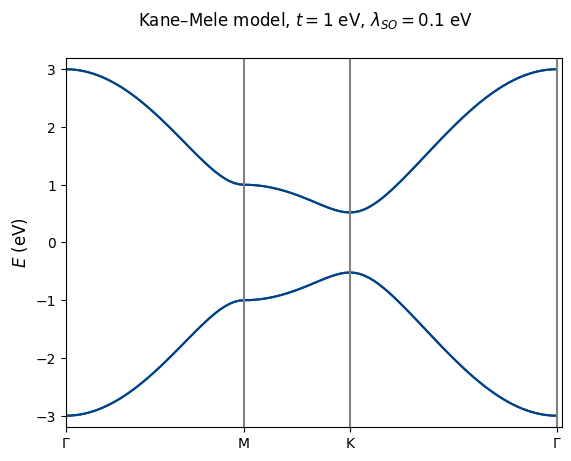

In [2]:
from PAOFLOW import GPAO

GPAO.GPAO().plot_bands(
    'kane_mele/bands_0.dat',
    sym_points='kane_mele/kpath_points.txt',
    title=r'Kane–Mele model, $t = 1$ eV, $\lambda_{SO} = 0.1$ eV',
    label=r'$E$ (eV)',
    y_lim=(-3.2, 3.2),
    cols='#004488',
);

Each band is twofold degenerate, because the model has both time-reversal and inversion symmetry. The spin–orbit term opens a gap of 1.0392 eV at $K$, between $-0.520$ and 0.520 eV, equal to $6\sqrt{3}\,\lambda_{SO}$; the energy zero is the middle of the gap, where the model is half filled. Without spin–orbit coupling the bands would touch at $K$, as in graphene, so the gap is the first sign that the occupied bands differ from those of a trivial insulator. Sections 2 and 4 show in what way.

## 2. The spin Hall conductivity and its plateau in the gap

You now compute the spin Hall conductivity $\sigma^z_{xy}$, the current of spin $s_z$ along $x$ driven by an electric field along $y$. `spin_Hall()` evaluates the Kubo formula as a sum over states of the spin Berry curvature,

$$
\Omega^z_{n}(\mathbf{k}) = -2 \sum_{m \ne n}
  \frac{\mathrm{Im}\bigl[j^{z}_{x,nm}(\mathbf{k})\, v^y_{mn}(\mathbf{k})\bigr]}
       {(\varepsilon_{n\mathbf{k}} - \varepsilon_{m\mathbf{k}})^2 + \delta^2} ,
\qquad
\sigma^z_{xy}(E) = \frac{1}{N_\mathrm{mesh} A} \sum_{\mathbf{k}} \sum_n f_{n\mathbf{k}}(E)\, \Omega^z_{n}(\mathbf{k}) ,
$$

where $v^i = \partial H / \partial k_i$ are the velocity matrices of Tutorial 01 in the band basis, $j^z_x = \tfrac12\{s_z, v^x\}$ is the spin current with $s_z = \sigma_z/2$, $f_{n\mathbf{k}}(E)$ is the occupation at Fermi energy $E$ with the adaptive Gaussian widths of Section 1, and $A$ is the area of the cell. `twoD=True` divides by the area instead of the volume, so the result is a sheet conductivity in units with $\hbar = e = 1$, in which the quantum of the spin Hall conductivity, $e/2\pi$, is $1/2\pi = 0.159155$. The broadening $\delta$ (`delta`, default 0.05 eV) keeps the denominators finite where two bands nearly touch, at the price of a small error in the result, so the run below computes the plateau for two values of it.

`s_tensor=[[0, 1, 2]]` selects the current direction $x$, the field direction $y$ and the spin direction $z$. `emin` and `emax` span all four bands, so that the scan covers every filling of the model. `fermi_dw` and `fermi_up` set the energy window of the k-resolved curvature, discussed after the figure.

In [3]:
for delta in (0.005, 0.05):  # the default 0.05 eV last: its files are plotted below
    paoflow.spin_Hall(
        twoD=True,
        emin=-4.0,
        emax=4.0,
        s_tensor=[[0, 1, 2]],
        delta=delta,
        fermi_dw=-4.0,  # below the lowest band: the curvature map sums all occupied bands
        fermi_up=0.0,
    )
    energy, shc = np.loadtxt('kane_mele/shcEf_z_xy.dat', unpack=True)
    print(f'delta = {delta} eV: sigma at E = 0: {shc[np.abs(energy).argmin()]:.6f}')
print(f'1/2pi = {1 / (2 * np.pi):.6f}')

Spin Hall Conductivity in:                  3.603 sec


delta = 0.005 eV: sigma at E = 0: 0.159153


Spin Hall Conductivity in:                  1.604 sec


delta = 0.05 eV: sigma at E = 0: 0.158987
1/2pi = 0.159155


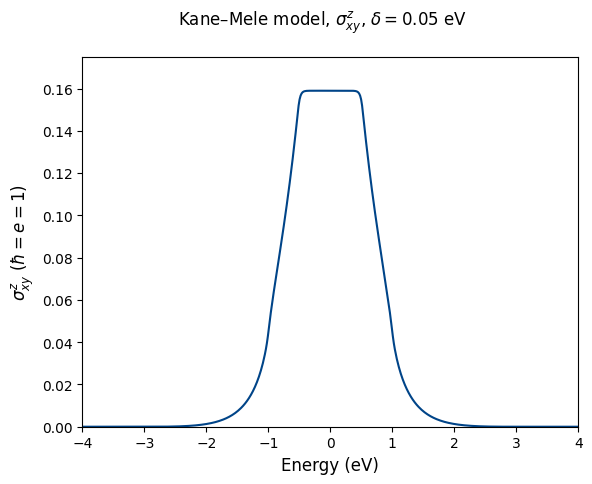

In [4]:
from PAOFLOW import GPAO

GPAO.GPAO().plot_shc(
    'kane_mele/shcEf_z_xy.dat',
    title=r'Kane–Mele model, $\sigma^z_{xy}$, $\delta = 0.05$ eV',
    x_lim=(-4.0, 4.0),
    cols='#004488',
    label=r'$\sigma^z_{xy}$ ($\hbar = e = 1$)',
)

Inside the gap, $\sigma^z_{xy}$ is constant at 0.158987, because moving $E$ through the gap does not change the occupied states. The value lies 0.1% below $1/2\pi$, and the run with $\delta = 0.005$ eV gives 0.159153, equal to $1/2\pi$ to five digits: the default broadening adds $\delta^2$ to denominators of the order of the gap squared and so lowers the plateau slightly. For a quantised result, choose $\delta$ much smaller than the gap. Outside the gap the conductivity falls as $E$ enters the bands, and it vanishes below $-3$ eV, where every band is empty, and above 3 eV, where every band is full and the curvatures of all bands add up to zero.

`spin_Hall()` also writes `Spin_Berry_z_xy.bxsf`, the k-resolved curvature $\sum_n [f_{n\mathbf{k}}(E_\mathrm{up}) - f_{n\mathbf{k}}(E_\mathrm{dw})]\,\Omega^z_n(\mathbf{k})$ on the mesh, with $E_\mathrm{dw}$ = `fermi_dw` and $E_\mathrm{up}$ = `fermi_up`. The defaults, $\mp 1$ eV, keep only the states near the gap. With `fermi_dw=-4.0`, below the lowest band, and `fermi_up=0.0`, the map holds the curvature of the occupied bands, and its average divided by $A$ is the plateau. Section 4 draws it next to the Berry curvature of the Haldane model, which explains its shape.

## 3. Berry phases on loops around a valley of gapped graphene

In this section you measure the Berry phase $\gamma$ of a band on a closed loop in k-space, the phase its Bloch states $|u_{n\mathbf{k}}\rangle$ acquire when carried around the loop, to find where in the zone the curvature sits, which the plateau of Section 2, a sum over all occupied states, does not tell. `berry_phase()` evaluates the discretised form of [R. Resta, Rev. Mod. Phys. 66, 899 (1994)](https://doi.org/10.1103/RevModPhys.66.899) on $N$ points of the loop,

$$
\gamma = -\arg \det \prod_{i=1}^{N} M(\mathbf{k}_i, \mathbf{k}_{i+1}) ,
\qquad
M_{mn}(\mathbf{k}_i, \mathbf{k}_{i+1}) = \langle u_{m\mathbf{k}_i} | u_{n\mathbf{k}_{i+1}} \rangle ,
$$

with $m$ and $n$ running over the bands listed in `sub` and $\mathbf{k}_{N+1} = \mathbf{k}_1$. The determinant makes $\gamma$ independent of the arbitrary phase of each eigenvector and, with several bands in `sub`, of their mixing. By Stokes' theorem $\gamma$ is the flux of the Berry curvature through the loop, defined modulo $2\pi$.

The system is spinless graphene with $t = -1$ eV and a sublattice potential $\pm\delta/2$ with $\delta = -0.2$ eV (`delta` of the `graphene` model, not the broadening of Section 2), which breaks inversion symmetry and opens a gap of 0.2 eV at $K$ and $K'$. Time reversal is preserved, so the curvature at $-\mathbf{k}$ is opposite to that at $\mathbf{k}$, and the two valleys carry opposite fluxes. Two shapes of loop are available. With `kspace_method='circle'` the loop is a circle of `nk1` points with radius `kradius` around `kcenter`, in crystal coordinates, so in Cartesian coordinates it is an ellipse; `closed=True` joins the last point to the first. With `kspace_method='square'` the rectangle `kxlim` × `kylim` is divided into plaquettes, and the phase around each goes to a file of three columns $k_x$, $k_y$, $\gamma$, with the plaquette corners in a second file ending in `_kgrid_corners.dat`. The sum of the plaquette phases is the flux through the rectangle, free of the $2\pi$ ambiguity as long as each plaquette encloses much less than $\pi$.

In [5]:
graphene = PAOFLOW.PAOFLOW(
    model={'label': 'graphene', 't': -1.0, 'delta': -0.2}, outputdir='graphene', verbose=False
)
k_prime = [1 / 3, 2 / 3, 0.0]


def circle_phase(fname):
    """The Berry phase on the last line of a 'circle' file."""
    return float(open(fname).read().split('Berry phase:')[1])


for sub, tag in (([0], 'lower'), ([1], 'upper'), ([0, 1], 'both')):
    graphene.berry_phase(
        kspace_method='circle',
        kcenter=k_prime,
        kradius=0.05,
        nk1=51,
        sub=sub,
        closed=True,
        method='berry',
        fname=f'circle_{tag}',
    )
    print(
        f'{tag:>5} band(s), circle of radius 0.05: {circle_phase(f"graphene/circle_{tag}.dat"):+.4f}'
    )

graphene.berry_phase(
    kspace_method='square',
    nk1=51,
    nk2=51,
    kxlim=[k_prime[0] - 0.05, k_prime[0] + 0.05],
    kylim=[k_prime[1] - 0.05, k_prime[1] + 0.05],
    sub=[0],
    method='berry',
    fname='patch_lower',
)
print(f'lower band, square of side 0.1: {np.loadtxt("graphene/patch_lower.dat")[:, 2].sum():+.4f}')


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.002 sec


Berry phase in:                             0.013 sec


lower band(s), circle of radius 0.05: +2.0688
Berry phase in:                             0.015 sec


upper band(s), circle of radius 0.05: -2.0688
Berry phase in:                             0.015 sec


 both band(s), circle of radius 0.05: -0.0000


Berry phase in:                             5.612 sec


lower band, square of side 0.1: +2.1786


Around $K'$ the two bands carry opposite phases, $\pm 2.0688$ on the circle and $\pm 2.18$ on the square that contains it, and together they give zero: the two bands span the whole space of the model at each $\mathbf{k}$, which has no phase to acquire. The phase on the square is larger than on the circle because the square encloses more of the curvature. A loop around a gapped valley therefore measures the flux through it, not a property of the valley. To see how much of the flux a loop encloses, repeat the circle for radii from 0.002 to 0.25, for the gapped model and for gapless graphene:

In [6]:
radii = [0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.18, 0.25]
gapless = PAOFLOW.PAOFLOW(
    model={'label': 'graphene', 't': -1.0, 'delta': 0.0}, outputdir='gapless', verbose=False
)
for model in (graphene, gapless):
    for radius in radii:
        model.berry_phase(
            kspace_method='circle',
            kcenter=k_prime,
            kradius=radius,
            nk1=201,
            sub=[0],
            closed=True,
            method='berry',
            fname=f'radius_{radius}',
        )

for name in ('graphene', 'gapless'):
    phases = [circle_phase(f'{name}/radius_{r}.dat') for r in radii]
    print(f'{name:>8}: ' + ' '.join(f'{p:+.3f}' for p in phases))


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.003 sec


Berry phase in:                             0.061 sec


Berry phase in:                             0.028 sec


Berry phase in:                             0.028 sec


Berry phase in:                             0.029 sec


Berry phase in:                             0.029 sec


... (12 outputs left out)

Berry phase in:                             0.031 sec


Berry phase in:                             0.031 sec


Berry phase in:                             0.046 sec


graphene: +0.021 +0.125 +0.419 +1.060 +1.532 +2.070 +2.434 +2.647 +2.784 +2.845
 gapless: +3.142 -3.142 -3.142 -3.142 +3.142 -3.142 +3.142 +3.142 +3.142 -3.142


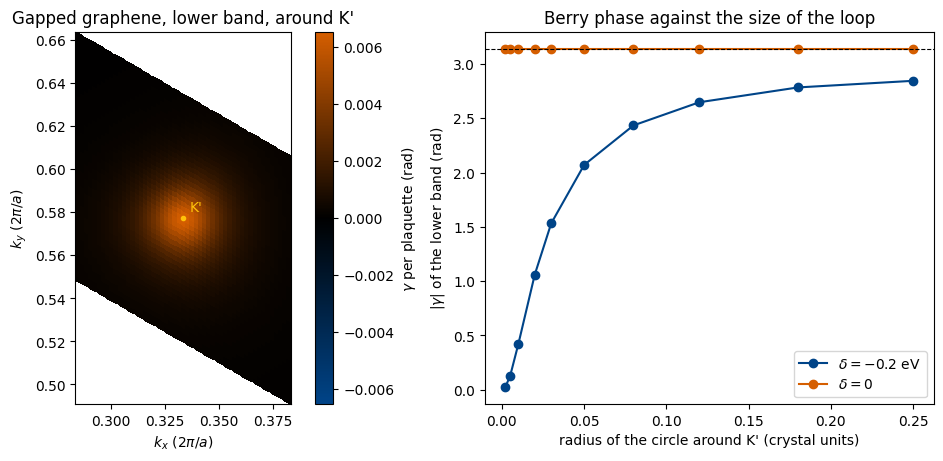

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

radii = [0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.18, 0.25]
cmap = LinearSegmentedColormap.from_list('palette', ['#004488', '#000000', '#D55E00'])
recip = np.array([[1.0, -1 / np.sqrt(3)], [0.0, 2 / np.sqrt(3)]])  # b1, b2 of the cell (2 pi / a)


def circle_phase(fname):
    return float(open(fname).read().split('Berry phase:')[1])


def square_phases(fname):
    """Plaquette corners (Cartesian) and Berry phase per plaquette of a 'square' run."""
    phase = np.loadtxt(fname)[:, 2]
    n = int(round(np.sqrt(phase.size)))
    corners = np.loadtxt(fname.replace('.dat', '_kgrid_corners.dat'))
    return corners.reshape(n + 1, n + 1, 2, order='F') @ recip, phase.reshape(n, n, order='F')


fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
k, phase = square_phases('graphene/patch_lower.dat')
vmax = np.abs(phase).max()
mesh = left.pcolormesh(k[..., 0], k[..., 1], phase, cmap=cmap, vmin=-vmax, vmax=vmax)
x, y = np.array([1 / 3, 2 / 3]) @ recip
left.plot(x, y, '.', color='#FFC20A', ms=6)
left.annotate("K'", (x, y), xytext=(5, 5), textcoords='offset points', color='#FFC20A')
left.set_aspect('equal')
left.set_title("Gapped graphene, lower band, around K'")
left.set_xlabel(r'$k_x$ ($2\pi/a$)')
left.set_ylabel(r'$k_y$ ($2\pi/a$)')
fig.colorbar(mesh, ax=left, label=r'$\gamma$ per plaquette (rad)')

for name, label, color in (
    ('graphene', r'$\delta = -0.2$ eV', '#004488'),
    ('gapless', r'$\delta = 0$', '#D55E00'),
):
    right.plot(
        radii,
        [abs(circle_phase(f'{name}/radius_{r}.dat')) for r in radii],
        'o-',
        color=color,
        label=label,
    )
right.axhline(np.pi, color='#000000', lw=0.8, ls='--')
right.set_xlabel("radius of the circle around K' (crystal units)")
right.set_ylabel(r'$|\gamma|$ of the lower band (rad)')
right.set_title('Berry phase against the size of the loop')
right.legend()
plt.show()

The map on the left shows the phase per plaquette of the square around $K'$. The curvature is spread over a disc around the valley, in contrast to gapless graphene, where it is concentrated at the Dirac point; the map shows $K'$ in amber. The curve on the right measures the same spread from the circles. For gapless graphene every loop gives $\pm\pi$, the sign being undefined modulo $2\pi$. With the gap, a small loop encloses almost nothing (0.021 rad at radius 0.002), half of $\pi$ is reached near radius 0.03, and the largest loop, 0.25, still misses 0.30 rad. A smaller gap shrinks the disc, and in the limit of no gap it collapses onto the Dirac point, which is why the gapless phase is $\pi$ on any loop. Only the flux through the whole zone, or through a region that holds all the curvature of a valley, is independent of the loop, and that is the subject of the next section.

## 4. Chern numbers: the Berry flux through the whole zone

You now integrate the curvature of one band over the whole Brillouin zone, which gives its Chern number,

$$
C = \frac{1}{2\pi} \int_\mathrm{BZ} \Omega(\mathbf{k})\, d^2k = \frac{1}{2\pi} \sum_\mathrm{plaquettes} \gamma ,
$$

an integer for a band separated from the others by a gap everywhere in the zone. With `kspace_method='square'`, `kxlim=[0.0, 1.0]` and `kylim=[0.0, 1.0]` the plaquettes tile one reciprocal cell. You compute it for gapped graphene and for the Haldane model of [F. D. M. Haldane, Phys. Rev. Lett. 61, 2015 (1988)](https://doi.org/10.1103/PhysRevLett.61.2015), a honeycomb lattice with one orbital per site and a complex second-neighbour hopping $t_2 e^{i\phi}$. The phase $\phi$ breaks time reversal, so the curvatures at $K$ and $K'$ need not cancel. With no sublattice potential and $\phi = \pi/2$ the gap is $6\sqrt{3}\,|t_2|$ at both valleys. The model comes from PythTB through the label `haldane_pythtb`, with `delta` the sublattice potential, `t1` and `t2` the first- and second-neighbour hoppings, and `phi` the phase.

In [8]:
graphene.berry_phase(
    kspace_method='square',
    nk1=60,
    nk2=60,
    kxlim=[0.0, 1.0],
    kylim=[0.0, 1.0],
    sub=[0],
    method='berry',
    fname='zone_lower',
)

haldane_model = {'label': 'haldane_pythtb', 'delta': 0.0, 't1': -1.0, 't2': 0.15, 'phi': np.pi / 2}
haldane = PAOFLOW.PAOFLOW(model=haldane_model, outputdir='haldane', verbose=False)
haldane.bands(ibrav=4, nk=600, band_path='G-M-K-G', high_sym_points=points)
haldane.berry_phase(
    kspace_method='square',
    nk1=60,
    nk2=60,
    kxlim=[0.0, 1.0],
    kylim=[0.0, 1.0],
    sub=[0],
    method='berry',
    fname='zone_lower',
)

bands = np.loadtxt('haldane/bands_0.dat')[:, 1:]
print(
    f'Haldane gap {bands[:, 1].min() - bands[:, 0].max():.4f} eV, 6 sqrt(3) |t2| = {6 * np.sqrt(3) * 0.15:.4f} eV'
)
for name in ('graphene', 'haldane'):
    phase = np.loadtxt(f'{name}/zone_lower.dat')[:, 2]
    print(
        f'{name:>8}, lower band: C = {phase.sum() / (2 * np.pi):+.4f}, largest plaquette phase {np.abs(phase).max():.3f} rad'
    )

Berry phase in:                            16.488 sec



────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.048 sec


Bands in:                                   0.149 sec


Berry phase in:                            15.416 sec


Haldane gap 1.5588 eV, 6 sqrt(3) |t2| = 1.5588 eV
graphene, lower band: C = -0.0000, largest plaquette phase 0.352 rad
 haldane, lower band: C = -1.0000, largest plaquette phase 0.009 rad


Kane-Mele spin Berry curvature: largest 4.99 bohr^2, average 0.4917 bohr^2
average / cell area (3.0926 bohr^2) = 0.158988


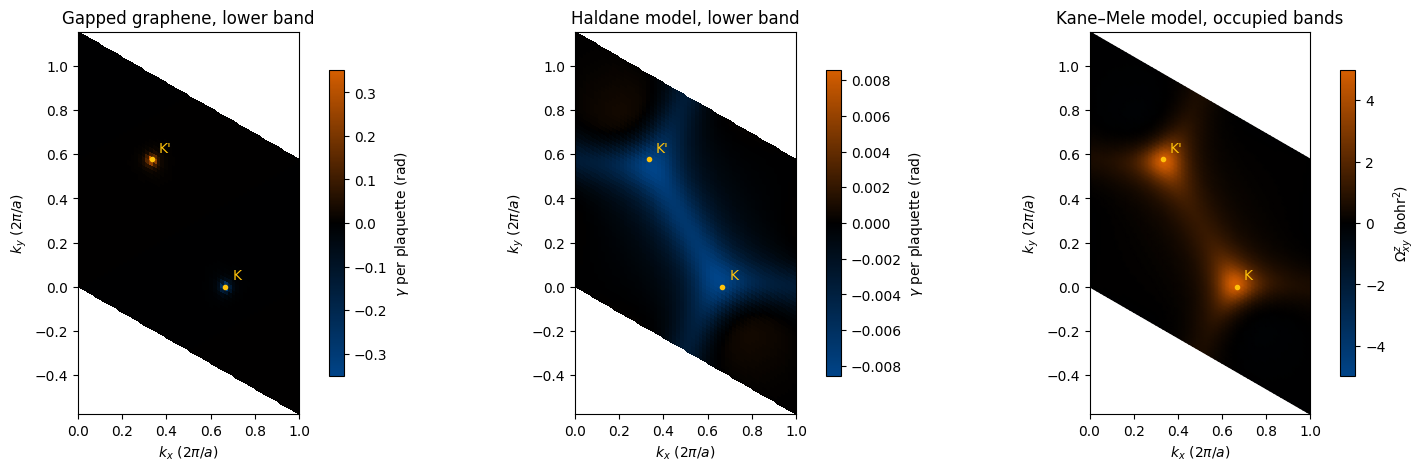

In [9]:
import contextlib
import io

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from PAOFLOW.gen.fermi_plotter import read_fermi_bxsf

cmap = LinearSegmentedColormap.from_list('palette', ['#004488', '#000000', '#D55E00'])
recip = np.array([[1.0, -1 / np.sqrt(3)], [0.0, 2 / np.sqrt(3)]])  # b1, b2 of the cell (2 pi / a)


def square_phases(fname):
    """Plaquette corners (Cartesian) and Berry phase per plaquette of a 'square' run."""
    phase = np.loadtxt(fname)[:, 2]
    n = int(round(np.sqrt(phase.size)))
    corners = np.loadtxt(fname.replace('.dat', '_kgrid_corners.dat'))
    return corners.reshape(n + 1, n + 1, 2, order='F') @ recip, phase.reshape(n, n, order='F')


with contextlib.redirect_stdout(io.StringIO()):  # the reader reports the two identical bands
    spin_berry = read_fermi_bxsf('kane_mele/Spin_Berry_z_xy.bxsf')
n1, n2, _ = spin_berry.dims
omega = spin_berry.bands[1][:, :, 0]  # bohr^2; the grid repeats its first point at the end
grid = np.stack(np.meshgrid(np.linspace(0, 1, n1), np.linspace(0, 1, n2), indexing='ij'), axis=-1)
area = np.sqrt(3) / 2 * 1.8897261**2  # the Kane-Mele cell: a = 1 Angstrom, in bohr^2
mean = omega[:-1, :-1].mean()
print(
    f'Kane-Mele spin Berry curvature: largest {omega.max():.2f} bohr^2, average {mean:.4f} bohr^2'
)
print(f'average / cell area ({area:.4f} bohr^2) = {mean / area:.6f}')

panels = [
    (
        *square_phases('graphene/zone_lower.dat'),
        'Gapped graphene, lower band',
        r'$\gamma$ per plaquette (rad)',
    ),
    (
        *square_phases('haldane/zone_lower.dat'),
        'Haldane model, lower band',
        r'$\gamma$ per plaquette (rad)',
    ),
    (grid @ recip, omega, 'Kane–Mele model, occupied bands', r'$\Omega^z_{xy}$ (bohr$^2$)'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, (k, value, title, label) in zip(axes, panels):
    vmax = np.abs(value).max()
    shading = 'flat' if k.shape[0] > value.shape[0] else 'gouraud'
    mesh = ax.pcolormesh(
        k[..., 0], k[..., 1], value, cmap=cmap, vmin=-vmax, vmax=vmax, shading=shading
    )
    for name, point in (('K', [2 / 3, 1 / 3]), ("K'", [1 / 3, 2 / 3])):
        x, y = np.array(point) @ recip
        ax.plot(x, y, '.', color='#FFC20A', ms=6)
        ax.annotate(name, (x, y), xytext=(5, 5), textcoords='offset points', color='#FFC20A')
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.set_xlabel(r'$k_x$ ($2\pi/a$)')
    ax.set_ylabel(r'$k_y$ ($2\pi/a$)')
    fig.colorbar(mesh, ax=ax, label=label, shrink=0.8)
plt.show()

Each panel covers one reciprocal cell, the parallelogram spanned by $\mathbf{b}_1$ and $\mathbf{b}_2$, in Cartesian coordinates in units of $2\pi/a$; zero is black, and $K$ and $K'$ are marked in amber.

In gapped graphene (left) the curvature of the lower band sits in discs around $K$ and $K'$ with opposite signs, the disc of Section 3 and its time-reversed partner, so the flux through the zone vanishes and $C = 0$: gapped graphene is a trivial insulator, whatever the phase on a loop around one valley. In the Haldane model (centre) the complex hopping gives the curvature the same sign at both valleys, and the phases add up to $C = -1$, an integer to four digits. Its curvature spreads over more of the zone, because the gap, 1.5588 eV, is almost eight times that of the gapped graphene. In both runs the largest plaquette phase stays well below $\pi$, which is the condition for the sum to be the flux; if a plaquette came close to $\pi$, you would increase `nk1` and `nk2`.

The Kane–Mele map (right) closes the argument of Section 2. Its spin Berry curvature peaks at $K$ and $K'$ with the same sign, up to 4.99 bohr$^2$, as in the Haldane model, because each spin is a Haldane model whose hopping phase has the sign of its spin. The two spins therefore have opposite Chern numbers, $C_\uparrow = -C_\downarrow = \pm 1$, and the spin Hall conductivity, which with $s_z = \pm\tfrac12$ is $(C_\uparrow - C_\downarrow)/4\pi$ in these units, is $1/2\pi$. The map confirms this numerically: its average, 0.4917 bohr$^2$, divided by the area of the cell, 3.0926 bohr$^2$, gives 0.15899, the plateau of Section 2 at the same $\delta$.

## Where to go next

- [How to run PAOFLOW on a tight-binding model](../howtos/tight-binding-model.md) lists the other built-in models, and shows how to build a Slater–Koster model with your own parameters or pass a PythTB model of your own.
- [How to compute the non-linear optical response of a tight-binding model](../howtos/nonlinear-optics-model.md) uses the gapped graphene of Section 3, whose broken inversion symmetry allows a shift current and second-harmonic generation.
- {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.spin_Hall` and {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.berry_phase` list all arguments, including the Wilson loops along a path (`kspace_method='path'`) and the Zak phase of one-dimensional systems (`method='zak'`).

In [10]:
# The numbers the tutorial quotes, at the precision it quotes them.
km = np.loadtxt('kane_mele/bands_0.dat')[:, 1:]
km_gap = km[:, 2].min() - km[:, 1].max()
assert abs(km_gap - 1.0392) < 1e-4, f'Kane-Mele gap {km_gap:.4f} eV'

energy, shc = np.loadtxt('kane_mele/shcEf_z_xy.dat', unpack=True)
plateau = shc[np.abs(energy) < 0.3]
assert np.all(
    np.abs(plateau - 0.158987) < 2e-6
), f'SHC plateau {plateau.min():.6f}..{plateau.max():.6f}'

lower = circle_phase('graphene/circle_lower.dat')
assert abs(lower - 2.0688) < 1e-4, f"Berry phase of the lower band around K' {lower:.4f}"
radius_003 = circle_phase('graphene/radius_0.03.dat')
assert abs(radius_003 - 1.53) < 0.01, f'Berry phase on the circle of radius 0.03 {radius_003:.3f}'

chern = {
    n: np.loadtxt(f'{n}/zone_lower.dat')[:, 2].sum() / (2 * np.pi) for n in ('graphene', 'haldane')
}
assert abs(chern['graphene']) < 1e-4, f'Chern number of gapped graphene {chern["graphene"]:.5f}'
assert abs(chern['haldane'] + 1) < 1e-4, f'Chern number of the Haldane model {chern["haldane"]:.5f}'